# Inferencia — House Prices

Toma el modelo de producción del notebook 4.0, lee **los datos crudos del test** y escribe las
predicciones en el formato que espera Kaggle.

## El contrato del artefacto

`models/modelo_produccion.joblib` guarda un `Pipeline` de dos pasos: las 13 transformaciones
de ingeniería de características y, al final, el ElasticNet ganador. Eso define exactamente
qué se le da y qué devuelve:

| | |
|---|---|
| **Entra** | Las 30 columnas **crudas**, tal como vienen de `data/raw/test.csv`. Con faltantes, con texto, sin escalar |
| **Sale** | `log1p(SalePrice)`. Hay que aplicar `np.expm1` para leerlo en dólares |
| **Ajustado con** | Las 1458 filas de train (sin los outliers 524 y 1299) |

## Las dos reglas de este notebook

**1. Aquí no se ajusta nada.** No hay un solo `fit` en todo el cuaderno. Las medianas, las
modas, los percentiles de recorte, la media y la desviación del escalado y los niveles del
one-hot son los que el modelo aprendió de train, y se aplican al test sin recalcularse. Si el
test influyera en cualquiera de esos números, las predicciones estarían contaminadas por datos
que en producción no existirían todavía.

**2. No se lee `data/processed/test_features.csv`.** Ese archivo ya está transformado; pasarlo
por un modelo que vuelve a transformar aplicaría el pipeline dos veces —escalaría lo escalado,
logaritmaría lo logaritmado— y devolvería basura. La entrada correcta es el CSV crudo, y el
artefacto se encarga del resto. Una sola fuente de verdad.

## Estructura

| # | Sección | Qué hace |
|---|---|---|
| 1 | El modelo | Carga el artefacto y lee su ficha |
| 2 | La entrada | Carga `test.csv` crudo y comprueba que sirve |
| 3 | Diagnóstico | Qué trae el test que train no tenía, y qué paso lo absorbe |
| 4 | Predicción | Predice y deshace el logaritmo |
| 5 | Verificación | Siete comprobaciones antes de escribir nada |
| 6 | Gráficas | Distribución de las predicciones y contraste entre los dos modelos |
| 7 | Guardado | `data/processed/submission.csv` en formato Kaggle |

In [1]:
import sys
from pathlib import Path

import joblib
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# El paquete del proyecto vive en la raíz, un nivel arriba de notebooks/.
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

# joblib necesita esta clase en el espacio de nombres para recargar el pipeline.
from house_pricing.features import RellenarAnioGaraje  # noqa: F401

RAW_DIR = RAIZ / "data" / "raw"
PROCESSED_DIR = RAIZ / "data" / "processed"
MODELS_DIR = RAIZ / "models"

# Mismo estilo que el notebook de modelado, para que las figuras se lean igual.
AZUL, NARANJA, AGUA = "#2a78d6", "#eb6834", "#1baf7a"
TINTA, TINTA_SUAVE = "#0b0b0b", "#52514e"
SUPERFICIE, REJILLA = "#fcfcfb", "#e4e3df"

mpl.rcParams.update({
    "figure.facecolor": SUPERFICIE, "axes.facecolor": SUPERFICIE,
    "axes.edgecolor": REJILLA, "axes.labelcolor": TINTA_SUAVE, "axes.titlecolor": TINTA,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.titlepad": 10, "axes.labelsize": 9,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": REJILLA, "grid.linewidth": 0.8, "grid.linestyle": "-",
    "xtick.color": TINTA_SUAVE, "ytick.color": TINTA_SUAVE,
    "xtick.labelsize": 8.5, "ytick.labelsize": 8.5,
    "legend.frameon": False, "legend.fontsize": 8.5,
    "lines.linewidth": 2.0, "figure.dpi": 110,
})

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)


def miles(x, _=None):
    return f"{x / 1000:,.0f}k"


print("raíz del proyecto:", RAIZ)

2026-11-04 22:20:26.956 | INFO     | house_pricing.config:<module>:11 - PROJ_ROOT path is: C:\Users\dgarc\OneDrive\Escritorio\Maestria\4T_2026\Product_Mang\Clase_Cloud\house_pricing


raíz del proyecto: C:\Users\dgarc\OneDrive\Escritorio\Maestria\4T_2026\Product_Mang\Clase_Cloud\house_pricing


## 1. El modelo

El artefacto no es solo el pipeline: trae su ficha. Quién es, con qué configuración, con
cuántas filas se ajustó, qué error cabe esperar de él — y una advertencia explícita sobre ese
número.

**Esa advertencia importa.** Las métricas que viajan en el archivo son las de
`modelo_ganador.joblib`, el modelo hermano que se ajustó solo con el 80 % de train y se midió
contra el 20 % reservado. El modelo de producción es la misma receta con todas las filas, así
que ya vio ese 20 %: medirlo contra él daría un número optimista y vacío. Se espera que
prediga algo mejor que su hermano —tiene un 25 % más de datos— pero **cuánto mejor no se puede
saber con los datos disponibles**, y el archivo lo dice en vez de dejar que alguien lo suponga.

In [2]:
artefacto = joblib.load(MODELS_DIR / "modelo_produccion.joblib")

modelo = artefacto["pipeline"]
FEATURES = artefacto["features"]

print(f"modelo         {artefacto['nombre']}")
print(f"configuración  {artefacto['mejor_config']}")
print(f"entrada        {artefacto['entrada']}")
print(f"salida         {artefacto['salida']}")
print(f"ajustado con   {artefacto['ajustado_con']}")
print(f"features       {len(FEATURES)} columnas crudas")

print(f"\nerror esperado (medido en el modelo hermano de 80 %):")
for clave, valor in artefacto["error_esperado"].items():
    print(f"  {clave:12} {valor:,.4f}" if valor < 1 else f"  {clave:12} {valor:,.0f} USD")

print(f"\nadvertencia guardada en el artefacto:\n  {artefacto['advertencia']}")

print(f"\npasos del pipeline ({len(modelo.named_steps['features'].steps)} de features + 1 modelo):")
for i, (nombre, transformador) in enumerate(modelo.named_steps["features"].steps, 1):
    print(f"  {i:2}. {nombre:22} {type(transformador).__name__}")
print(f"  ->  {type(modelo.named_steps['modelo']).__name__}")

modelo         ElasticNet
configuración  alpha=0.001, l1_ratio=0.5
entrada        las 30 columnas crudas de data/raw, sin transformar
salida         log1p(SalePrice) · aplicar np.expm1 para volver a dólares
ajustado con   1458 filas (train completo, sin los outliers 524 y 1299)
features       30 columnas crudas

error esperado (medido en el modelo hermano de 80 %):
  rmse_log     0.1401
  rmse_real    20,042 USD
  nrmse_rango  0.0401

advertencia guardada en el artefacto:
  Estas métricas son las del modelo hermano modelo_ganador.joblib, ajustado solo con el 80 %. Este modelo ya vio las filas de validación: medirlo contra ellas daría una cifra optimista y sin significado.

pasos del pipeline (13 de features + 1 modelo):
   1. indicador_sin_garaje   AddMissingIndicator
   2. anio_garaje            RellenarAnioGaraje
   3. estructural_cat        CategoricalImputer
   4. estructural_num        ArbitraryNumberImputer
   5. aleatorio_5_a_20       RandomSampleImputer
   6. mediana_hasta_5   

## 2. La entrada — el test crudo

`data/raw/test.csv` tiene **1459 filas y ninguna puede perderse**: Kaggle espera una
predicción por cada `Id`. Esa es la diferencia operativa con el entrenamiento, donde sí se
eliminaron dos outliers. Aquí no se filtra, no se imputa a mano y no se corrige nada: lo que
haya de raro en el test es trabajo del pipeline.

Se separan dos cosas del CSV: la columna `Id`, que no es una variable y solo sirve para
etiquetar la salida, y las 30 columnas que el modelo espera, **en el mismo orden** en que las
vio al entrenarse. El orden importa porque varios transformadores de feature-engine operan
por nombre, pero el `assert` de abajo verifica nombre y posición de todos modos: un
desalineamiento silencioso es la clase de error que produce predicciones plausibles y falsas.

In [3]:
test_crudo = pd.read_csv(RAW_DIR / "test.csv")

ids = test_crudo["Id"].copy()
X_test = test_crudo[FEATURES].copy()

faltan = [c for c in FEATURES if c not in test_crudo.columns]
assert not faltan, f"el test no trae estas columnas: {faltan}"
assert list(X_test.columns) == FEATURES, "las columnas no están en el orden del entrenamiento"
assert len(X_test) == 1459, f"el test debería tener 1459 filas, tiene {len(X_test)}"
assert ids.is_unique, "hay Id repetidos en el test"

tipos = X_test.dtypes.astype(str).value_counts()

print(f"test crudo: {test_crudo.shape[0]} filas × {test_crudo.shape[1]} columnas")
print(f"se usan {len(FEATURES)} columnas · Id de {ids.min()} a {ids.max()}")
print(f"\ntipos de las 30 features:")
for tipo, cuenta in tipos.items():
    print(f"  {tipo:10} {cuenta}")
print("\nlas 4 comprobaciones de entrada pasan ✓")

test crudo: 1459 filas × 80 columnas
se usan 30 columnas · Id de 1461 a 2919

tipos de las 30 features:
  str        15
  int64      8
  float64    7

las 4 comprobaciones de entrada pasan ✓


## 3. Diagnóstico — lo que el test trae y el entrenamiento no

Esta sección no cambia nada: solo mira. Sirve para saber **qué tan lejos está el test de los
datos con los que se ajustó el modelo**, antes de confiar en una sola predicción.

Tres cosas que revisar, y las tres son conocidas de este dataset:

**Faltantes.** El test tiene faltantes en columnas donde train no tenía ninguno —`MSZoning`,
`Exterior1st`, `Exterior2nd`, `SaleType`, `KitchenQual`— casi siempre en una o dos filas
sueltas. El pipeline los absorbe con la moda aprendida de train, que es exactamente para lo
que estaba ese paso. Los faltantes masivos (`MasVnrType`, `FireplaceQu`, `GarageFinish`) son
**estructurales**: no son datos perdidos sino ausencia de la característica, y se convierten
en `"None"` o en 0 según su tipo.

**Categorías nuevas.** Si el test trajera un barrio que train nunca vio, su dummy no existiría
y el one-hot lo dejaría en ceros; el codificador ordinal le pondría −1. Ninguna de las dos
cosas rompe la predicción, pero conviene saber si pasa.

**Valores imposibles.** Hay una casa con `GarageYrBlt = 2207`, un error de captura
documentado desde el notebook 2. El transformador `RellenarAnioGaraje` lo reemplaza por
`YearBuilt` sin que haya que tocar nada aquí.

In [4]:
# --- faltantes, y qué paso del pipeline se encarga de cada uno ---
# Train se carga solo como referencia, para contrastar contra lo que el modelo vio.
# Se le quitan los dos outliers que el notebook 4.0 excluyó: si se dejaran, las cifras
# de esta sección describirían un conjunto distinto del que el modelo aprendió.
train_crudo = pd.read_csv(RAW_DIR / "train.csv")
train_crudo = train_crudo[~train_crudo["Id"].isin([524, 1299])].reset_index(drop=True)
assert len(train_crudo) == 1458, "la referencia de train no coincide con la del entrenamiento"

na_test = X_test.isna().sum()
na_train = train_crudo[FEATURES].isna().sum()

ESTRUCTURALES = {"MasVnrType", "FireplaceQu", "GarageType", "GarageFinish", "BsmtQual",
                 "BsmtFinType1", "MasVnrArea", "BsmtFinSF1", "TotalBsmtSF", "GarageCars",
                 "GarageArea"}

diagnostico = pd.DataFrame({
    "na_test": na_test,
    "na_train": na_train,
    "tipo": ["estructural (ausencia)" if c in ESTRUCTURALES else "genuino (dato perdido)"
             for c in FEATURES],
    "solo_en_test": (na_test > 0) & (na_train == 0),
})
con_na = diagnostico[diagnostico["na_test"] > 0].sort_values("na_test", ascending=False)

print(f"columnas con faltantes en test: {len(con_na)} de {len(FEATURES)}")
print(f"faltantes totales: {int(na_test.sum()):,}")
print(f"columnas con faltantes que train no tenía: {int(diagnostico['solo_en_test'].sum())}\n")
print(con_na.to_string())

# --- categorías que el modelo nunca vio ---
categoricas = [c for c in FEATURES if not pd.api.types.is_numeric_dtype(X_test[c])]
nuevas = {c: sorted(set(X_test[c].dropna().unique()) - set(train_crudo[c].dropna().unique()))
          for c in categoricas}
nuevas = {c: v for c, v in nuevas.items() if v}

print(f"\ncategorías presentes en test y ausentes en train: "
      f"{'ninguna' if not nuevas else nuevas}")

# --- valores imposibles ---
anio_max = int(X_test["GarageYrBlt"].max())
fuera = int((X_test["GarageYrBlt"] > 2010).sum())
print(f"\nGarageYrBlt: máximo {anio_max} · {fuera} fila(s) posterior(es) a 2010 "
      f"-> las corrige RellenarAnioGaraje")

columnas con faltantes en test: 17 de 30
faltantes totales: 2,154
columnas con faltantes que train no tenía: 9

              na_test  na_train                    tipo  solo_en_test
MasVnrType        894       872  estructural (ausencia)         False
FireplaceQu       730       690  estructural (ausencia)         False
LotFrontage       227       259  genuino (dato perdido)         False
GarageFinish       78        81  estructural (ausencia)         False
GarageYrBlt        78        81  genuino (dato perdido)         False
GarageType         76        81  estructural (ausencia)         False
BsmtQual           44        37  estructural (ausencia)         False
MasVnrArea         15         8  estructural (ausencia)         False
MSZoning            4         0  genuino (dato perdido)          True
TotalBsmtSF         1         0  estructural (ausencia)          True
KitchenQual         1         0  genuino (dato perdido)          True
GarageArea          1         0  estructural (au

## 4. Predicción

Dos líneas, y la segunda es la que se olvida.

El modelo devuelve `log1p(SalePrice)` porque así se entrenó. `np.expm1` deshace exactamente
esa transformación —es la inversa de `log1p`, no una aproximación— y devuelve dólares.
Olvidarla produce un archivo con precios alrededor de 12, que Kaggle acepta sin protestar y
puntúa pésimo.

Un matiz que ya se discutió en el notebook de modelado: `expm1` de una predicción hecha en
logaritmos se parece más a la **mediana** condicional que a la media, así que las predicciones
quedan levemente por debajo de lo que daría un modelo entrenado en dólares. No se corrige,
porque la métrica de la competencia se evalúa sobre logaritmos y corregirlo empeoraría
justamente eso.

In [5]:
prediccion_log = modelo.predict(X_test)
prediccion = np.expm1(prediccion_log)

resumen = pd.Series(prediccion).describe()[["min", "25%", "50%", "75%", "max"]]
referencia = train_crudo["SalePrice"].describe()[["min", "25%", "50%", "75%", "max"]]

comparacion = pd.DataFrame({
    "predicciones_test": resumen.round(0),
    "SalePrice_train": referencia.round(0),
}).astype(int)

print(f"{len(prediccion):,} predicciones generadas\n")
print(comparacion.to_string())
print(f"\nen logaritmo: media {prediccion_log.mean():.3f} · "
      f"sd {prediccion_log.std():.3f}")
print(f"en dólares:   media {prediccion.mean():,.0f} · "
      f"sd {prediccion.std():,.0f}")

1,459 predicciones generadas

     predicciones_test  SalePrice_train
min              44119            34900
25%             125244           129925
50%             157404           163000
75%             211159           214000
max             589374           755000

en logaritmo: media 12.008 · sd 0.393
en dólares:   media 177,627 · sd 75,569


## 5. Verificación — siete comprobaciones antes de escribir nada

Un archivo de predicciones con un `NaN`, un precio negativo o una fila de menos se descubre
tarde y siempre en el peor momento. Estas comprobaciones son `assert`: si alguna falla, el
notebook se detiene y no se escribe nada.

Las cuatro primeras son de forma —cuántas filas, en qué orden, sin huecos, sin imposibles— y
las tres últimas son de plausibilidad. Esas no pueden ser estrictas: el test **puede**
legítimamente contener una casa más cara que cualquiera de train. Lo que se comprueba es que
el conjunto de predicciones viva en el mismo orden de magnitud que los precios conocidos, y
que no haya un amontonamiento sospechoso de valores idénticos, que sería la firma de un
pipeline que falló en silencio y está devolviendo la misma constante.

In [6]:
minimo_train, maximo_train = train_crudo["SalePrice"].min(), train_crudo["SalePrice"].max()

# --- forma ---
assert len(prediccion) == len(X_test) == 1459, "el número de predicciones no cuadra"
assert not np.isnan(prediccion).any(), "hay NaN entre las predicciones"
assert not np.isinf(prediccion).any(), "hay infinitos entre las predicciones"
assert (prediccion > 0).all(), "hay precios negativos o cero"

# --- plausibilidad ---
assert prediccion.min() > minimo_train * 0.5, \
    f"hay predicciones absurdamente bajas: mínimo {prediccion.min():,.0f}"
assert prediccion.max() < maximo_train * 2, \
    f"hay predicciones absurdamente altas: máximo {prediccion.max():,.0f}"
valor_mas_repetido = pd.Series(prediccion).round(0).value_counts().iloc[0]
assert valor_mas_repetido < 10, \
    f"{valor_mas_repetido} predicciones idénticas: el pipeline puede estar devolviendo una constante"

print("las 7 comprobaciones pasan ✓\n")
print(f"rango de las predicciones  {prediccion.min():>9,.0f} a {prediccion.max():>9,.0f}")
print(f"rango de SalePrice en train{minimo_train:>10,.0f} a {maximo_train:>9,.0f}")
print(f"valores distintos          {len(np.unique(prediccion.round(0))):,} de {len(prediccion):,}")
print(f"predicciones fuera del rango visto en train: "
      f"{int(((prediccion < minimo_train) | (prediccion > maximo_train)).sum())}")

las 7 comprobaciones pasan ✓

rango de las predicciones     44,119 a   589,374
rango de SalePrice en train    34,900 a   755,000
valores distintos          1,453 de 1,459
predicciones fuera del rango visto en train: 0


## 6. Dos gráficas de control

**La primera compara distribuciones.** Si las predicciones del test se parecen a los precios
de train, el modelo está operando en terreno conocido. Se espera —y conviene verlo, no
suponerlo— que la curva de las predicciones sea **más estrecha**: un modelo que estima el
valor esperado de cada casa nunca reproduce la variabilidad real, porque no predice el azar
que empuja una venta concreta por encima o por debajo de lo que valdría la casa promedio con
esas características. Las colas comprimidas son una propiedad de cualquier regresión, no un
defecto de esta.

**La segunda contrasta los dos modelos.** El de producción y el del torneo son la misma receta
con 292 casas de diferencia. Sus predicciones sobre el test deberían caer casi sobre la
diagonal: si se separaran mucho, significaría que el modelo es demasiado sensible a qué filas
le tocaron, y ninguna de las dos versiones sería de fiar.

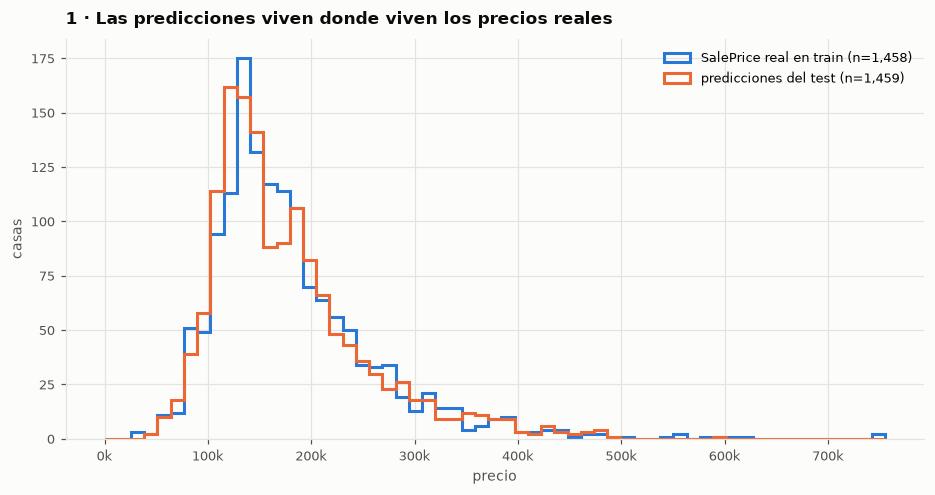

desviación estándar · train          79,495
desviación estándar · predicciones    75,569
la predicción comprime la dispersión al 95% (esperado: una regresión no predice el azar)


In [7]:
# --- Figura 1: ¿predice el modelo en terreno conocido? ---
fig, ax = plt.subplots(figsize=(8.6, 4.6))

bins = np.linspace(0, max(train_crudo["SalePrice"].max(), prediccion.max()), 60)
ax.hist(train_crudo["SalePrice"], bins=bins, histtype="step", linewidth=2,
        color=AZUL, label=f"SalePrice real en train (n={len(train_crudo):,})")
ax.hist(prediccion, bins=bins, histtype="step", linewidth=2,
        color=NARANJA, label=f"predicciones del test (n={len(prediccion):,})")

ax.xaxis.set_major_formatter(mpl.ticker.FuncFormatter(miles))
ax.set_xlabel("precio")
ax.set_ylabel("casas")
ax.set_title("1 · Las predicciones viven donde viven los precios reales")
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()

print(f"desviación estándar · train       {train_crudo['SalePrice'].std():>9,.0f}")
print(f"desviación estándar · predicciones{prediccion.std():>10,.0f}")
print(f"la predicción comprime la dispersión al "
      f"{prediccion.std() / train_crudo['SalePrice'].std():.0%} "
      "(esperado: una regresión no predice el azar)")

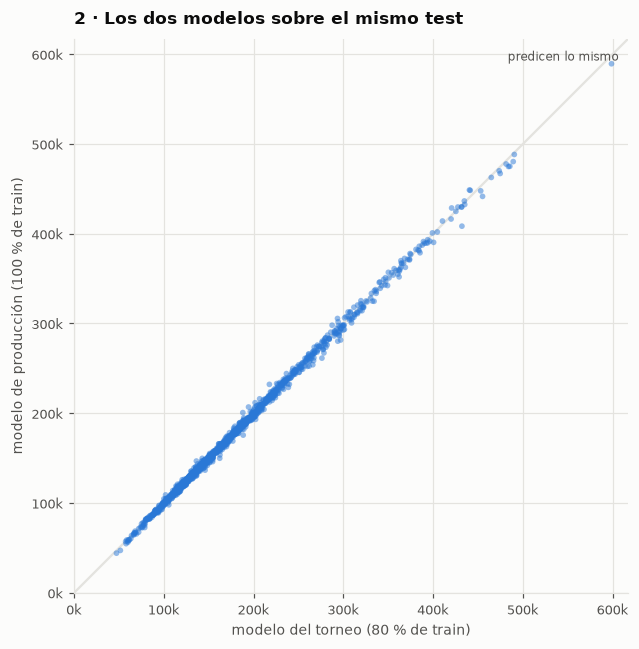

correlación entre ambos          0.99922
diferencia media (con signo)          -556 USD
diferencia absoluta mediana          1,477 USD
diferencia absoluta máxima          23,617 USD
casas que se mueven más de 10 mil: 19 de 1,459


In [8]:
# --- Figura 2: ¿cambió algo reentrenar con el 20 % restante? ---
modelo_torneo = joblib.load(MODELS_DIR / "modelo_ganador.joblib")["pipeline"]
prediccion_torneo = np.expm1(modelo_torneo.predict(X_test))

diferencia = prediccion - prediccion_torneo

fig, ax = plt.subplots(figsize=(6.4, 6.0))
tope = float(max(prediccion.max(), prediccion_torneo.max())) * 1.03

ax.plot([0, tope], [0, tope], color=REJILLA, linewidth=1.5, zorder=1)
ax.scatter(prediccion_torneo, prediccion, s=14, color=AZUL, alpha=0.5,
           edgecolor="none", zorder=2)
ax.annotate("predicen lo mismo", xy=(tope, tope), xytext=(-6, -14),
            textcoords="offset points", ha="right", fontsize=8, color=TINTA_SUAVE)

ax.set_xlim(0, tope)
ax.set_ylim(0, tope)
ax.set_aspect("equal")
ax.xaxis.set_major_formatter(mpl.ticker.FuncFormatter(miles))
ax.yaxis.set_major_formatter(mpl.ticker.FuncFormatter(miles))
ax.set_xlabel("modelo del torneo (80 % de train)")
ax.set_ylabel("modelo de producción (100 % de train)")
ax.set_title("2 · Los dos modelos sobre el mismo test")
plt.tight_layout()
plt.show()

print(f"correlación entre ambos          {np.corrcoef(prediccion, prediccion_torneo)[0, 1]:.5f}")
print(f"diferencia media (con signo)     {diferencia.mean():>+9,.0f} USD")
print(f"diferencia absoluta mediana      {np.median(np.abs(diferencia)):>9,.0f} USD")
print(f"diferencia absoluta máxima       {np.abs(diferencia).max():>9,.0f} USD")
print(f"casas que se mueven más de 10 mil: "
      f"{int((np.abs(diferencia) > 10_000).sum())} de {len(diferencia):,}")

## 7. Guardado

`data/processed/submission.csv`, en el formato exacto que pide la competencia: dos columnas,
`Id` y `SalePrice`, 1459 filas, precios en dólares.

La verificación final compara el archivo escrito contra `data/raw/sample_submission.csv` —el
ejemplo que publica Kaggle— columna por columna y `Id` por `Id`. No basta con que las dos
tablas tengan el mismo tamaño: los `Id` deben coincidir **en el mismo orden**, porque una
permutación produciría un archivo perfectamente válido donde cada precio pertenece a otra
casa, y el único síntoma sería una puntuación mala sin explicación.

In [9]:
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
ruta_submission = PROCESSED_DIR / "submission.csv"

submission = pd.DataFrame({"Id": ids.to_numpy(), "SalePrice": prediccion})
submission.to_csv(ruta_submission, index=False)

# Verificación contra el ejemplo oficial: mismas columnas, mismas filas, mismos Id en orden.
ejemplo = pd.read_csv(RAW_DIR / "sample_submission.csv")
escrito = pd.read_csv(ruta_submission)

assert list(escrito.columns) == list(ejemplo.columns), \
    f"columnas distintas: {list(escrito.columns)} vs {list(ejemplo.columns)}"
assert len(escrito) == len(ejemplo), f"{len(escrito)} filas, se esperaban {len(ejemplo)}"
assert (escrito["Id"].to_numpy() == ejemplo["Id"].to_numpy()).all(), \
    "los Id no coinciden con el sample_submission, o están en otro orden"
assert escrito["SalePrice"].notna().all(), "el archivo escrito tiene SalePrice vacíos"
assert np.allclose(escrito["SalePrice"], prediccion), \
    "el archivo no contiene las predicciones calculadas"

print(f"{ruta_submission.relative_to(RAIZ)}  "
      f"({ruta_submission.stat().st_size / 1024:,.1f} KB)")
print("las 5 comprobaciones del archivo pasan ✓\n")
print(escrito.head().to_string(index=False))
print("...")
print(escrito.tail(3).to_string(index=False, header=False))
print(f"\n{len(escrito):,} filas · precios de {escrito['SalePrice'].min():,.0f} "
      f"a {escrito['SalePrice'].max():,.0f} USD")

data\processed\submission.csv  (35.1 KB)
las 5 comprobaciones del archivo pasan ✓

  Id     SalePrice
1461 117930.888124
1462 154461.272624
1463 177721.630881
1464 187624.206264
1465 198581.323907
...
2917 160377.630557
2918 116872.815154
2919 225929.912362

1,459 filas · precios de 44,119 a 589,374 USD


## 8. Cierre

El archivo está listo para subir. Lo que hay detrás de cada número, en una línea: las 30
columnas crudas de una casa del test entraron a un pipeline que las imputó, codificó, recortó,
transformó y escaló **con los parámetros aprendidos de train**, y un ElasticNet con
`alpha=0.001` y `l1_ratio=0.5` devolvió un logaritmo que `expm1` convirtió en dólares.

**Qué error esperar.** Alrededor de **20 mil dólares** de RMSE, un 4 % del rango de precios.
Esa cifra viene de medir al modelo hermano contra 292 casas que no había visto, y es la mejor
estimación disponible para este modelo — probablemente algo pesimista, porque el de producción
entrenó con un 25 % más de datos. La puntuación oficial de Kaggle se calcula sobre el RMSE
logarítmico, donde la referencia es **0.14**.

**Qué no demuestra este notebook.** Que las predicciones sean buenas. Las siete comprobaciones
de la sección 5 verifican que sean *posibles* —sin huecos, positivas, en el orden de magnitud
correcto, bien alineadas con sus `Id`—, no que sean acertadas. Lo único que respalda su
calidad es el torneo del notebook 4.0, y lo hace sobre casas distintas de estas.